# Pycavi zero point calibration check

This notebook checks the calibration of swarped image calibrated in the previous step.

- Reads the swarped image and some necessary keywords.
- Read the catalogue used to calibrate the image.
- Produce several plots that can be used to determine the quality of the photometry.
- Saves the resulting plot into a file



In [1]:
import os
import sys
import glob
import copy
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib import cm
from astropy.stats import sigma_clipped_stats
from astropy.visualization import simple_norm
from astropy.coordinates import SkyCoord
from astropy import units as u
from astropy.io import fits
from astropy.wcs import WCS

from photutils.aperture import SkyCircularAperture, SkyCircularAnnulus, aperture_photometry


from pycavi_astromatic import SExtractor
import pycavi_tools

In [2]:
def plot_calibration_check(image_path, calibration_dir, swarp_dir):
    """
    Created 5 different check plots from the SExtractor photometry on the swarped OmegaCam frame.
    * Calibrated magnitudes vs Catalogue magnitudes
    * Catalogue - Calibrated magnitudes vs Catalogue magnitudes.
    * Catalogue - Calibrated magnitudes vs Catalogue colour. This one also check the systematic increase of magnitude
        in function of the distance from the center R.
    * Catalogue - Calibrated magnitudes vs R [distance from center] color coded Catalogue - Calibrated
    * A check image of the field
    
    ##########
    parameters
    
    phot_catalogue : str
        The path to the clean photometric reference catalogue created during the calibration process of the frame.
    sex_catalogue_path : str
        The path to the SExtractor output catalogue with the photometry of the frame.
    zp_cal : ZPCalibration
        The calibration object containing important information regarding the frame.
        
    ######
    output
    
    calibration image:
        A png image named OBJECT_BAND_calibration_check.png containing the aforementioned plots. It is saved on the
        calibration directory.
    
    """

    logging.info("pycavi qc phot: creating check plots")

    # We first read the image whose photometry will be checked
    logging.info("pycavi qc phot: reading image {}".format(image_path.split('/')[-1]))
    zp_data, zp_hdu = fits.getdata(image_path, header=True)

    # we load some data from the image to be checked
    keys_to_extract = {'band': "MEFPP QC BAND NAME",
                       'crval1': "CRVAL1",
                       'crval2': "CRVAL2",
                       'mag_max': "MEFPP QC PHO MAGMAX",
                       'mag_min': "MEFPP QC PHO MAGMIN",
                       'phot_rad': "MEFPP QC PHO RAD",
                       'phot_skyr1': "MEFPP QC PHO SKYR1",
                       'phot_skyr2': "MEFPP QC PHO SKYR2",
                       'phot_calfile': "MEFPP QC PHO CALFILE",
                       'magzp': "MAGZP"}

    input_dict = {}
    for akey, avalue in keys_to_extract.items():
        if avalue in list(zp_hdu.keys()):
            input_dict[akey]=zp_hdu[avalue]
        else:
            logging.info("pycavi qc phot: **** missing key {} in headers".format(avalue))
            
    # we create a class to hold all these data
    class ZPcal:
        def __init__(self, input_dict, zdata, zhdu):
            self.band = input_dict['band']
            self.crval1 = input_dict['crval1']
            self.crval2 = input_dict['crval2']
            self.mag_max = input_dict['mag_max']
            self.mag_min = input_dict['mag_min']
            self.phot_rad = input_dict['phot_rad']
            self.phot_skyr1 = input_dict['phot_skyr1']
            self.phot_skyr2 = input_dict['phot_skyr2']
            self.phot_calfile = input_dict['phot_calfile']
            self.magzp = input_dict['magzp']
            self.data = zdata
            self.wcs = wcs = WCS(zhdu)
            self.aperture = None
            self.sky_annulus = None
        
    zp_cal = ZPcal(input_dict, zp_data, zp_hdu)

    query_catalogue_path = calibration_dir+'/'+zp_cal.phot_calfile
    logging.info("pycavi qc phot: reading catalogue used for query {}".format(query_catalogue_path.split('/')[-1]))
    phot_catalogue = pd.read_csv(query_catalogue_path)

    # first load the ra, dec and magnitudes from both catalogues.
    ra_std = phot_catalogue["raj2000"].to_numpy() * u.deg
    de_std = phot_catalogue["dej2000"].to_numpy() * u.deg

    # select bands accordingly to frame band
    # if band is NB_659, then construct the scatter plot using r-i and r-Ha
    # in rest of cases uses g-band and band-OCam
    # except in g case where we use band-r and band-OCam
    if zp_cal.band == "NB_659":
        mag_std = phot_catalogue["r_SDSS"].to_numpy()
        mag_side_std = phot_catalogue["i_SDSS"].to_numpy()
        mag_std_band = "r_SDSS"
        mag_side_std_band = "i_SDSS"
    else:
        mag_std = phot_catalogue[zp_cal.band].to_numpy()
        mag_std_band = zp_cal.band
        if zp_cal.band == "g_SDSS":
            mag_side_std = phot_catalogue["r_SDSS"].to_numpy()
            mag_side_std_band = "r_SDSS"
        else:
            mag_side_std = phot_catalogue["g_SDSS"].to_numpy()
            mag_side_std_band = "g_SDSS"
    logging.info("pycavi qc phot: number of valid entries in calibrator catalogue: {}".format(len(mag_std)))
    
    # we read the sextractor catalogue created by previous notebook.
    # After testing we will change to do photometry with do_phot in
    # the positions of the query catalogue.
    #
    #sex_catalogue_path = image_path[:-5]+'.cat'
    #logging.info("pycavi qc pho: reading sextractor catalogue {}".format(sex_catalogue_path))
    #sex_catalogue = np.loadtxt(sex_catalogue_path)
    #mag_sex = sex_catalogue[:, 5]
    #ra_sex = sex_catalogue[:, 1]
    #de_sex = sex_catalogue[:, 2]

    # select only sextractor best sources (flags == 0 and class_star > 0.9)
    #flags = sex_catalogue[:, 7]
    #class_star = sex_catalogue[:, 10]

    # it was flags==0 and class_star >0.3
    #sel_best_stars = (flags == 0) & (class_star > 0.3)
    #ra_sex = ra_sex[sel_best_stars]
    #de_sex = de_sex[sel_best_stars]
    #mag_sex = mag_sex[sel_best_stars]
    #logging.info("number of valid entries in sex catalogue: {}".format(len(mag_sex)))
    ################################################################################################

    # Photometry is done directly on the frame
    ra_frm = copy.deepcopy(ra_std)
    de_frm = copy.deepcopy(de_std)
    logging.info("pycavi qc phot:  creating aperture object")
    positions = SkyCoord(ra=ra_frm, dec=de_frm, frame="icrs")
    zp_cal.aperture = SkyCircularAperture(positions, r=zp_cal.phot_rad * u.arcsec)
    zp_cal.sky_annulus = SkyCircularAnnulus(positions, zp_cal.phot_skyr1 * u.arcsec,
                                                zp_cal.phot_skyr2 * u.arcsec)

    logging.info("pycavi qc phot: doing aperture photometry on frame.")
    phot_table = aperture_photometry(zp_cal.data, zp_cal.aperture, wcs=zp_cal.wcs, method="exact")
    for col in phot_table.colnames:
        if col != "id" and col != "sky_center":
            phot_table[col].info.format = "%.2f"  # for consistent table output
            
    phot_disk_area = zp_cal.aperture.to_pixel(zp_cal.wcs).area
    logging.info("pycavi qc phot: phot_disk_area in pixels: {}".format(phot_disk_area))


    logging.info("pycavi qc phot: estimating backgrounds.")
    annulus_masks = zp_cal.sky_annulus.to_pixel(zp_cal.wcs).to_mask(method='center')
    logging.info("pycavi qc phot: number of objects: {}".format(len(annulus_masks)))
    bkg_median = np.empty(len(annulus_masks))
    bkg_median[:] = np.nan
    for i in range(len(annulus_masks)):
        mask = annulus_masks[i]
        annulus_data = mask.multiply(zp_cal.data)
        if annulus_data is not None:  # if we have data we use it
            annulus_data_1d = annulus_data[mask.data > -0]
            mean_sigclip, median_sigclip, _ = sigma_clipped_stats(annulus_data_1d, sigma_lower=3.0, sigma_upper=3.0)
            bkg_median[i] = median_sigclip

    # with the bkg median value, we can subtract from the circular aperture
    # Note that the aper_sum_bkgsub array will have invalid entries in the
    # form of nan and 0.0 values.
    logging.info("pycavi qc phot: subtracting backgrounds.")
    aper_bkg = bkg_median * phot_disk_area
    aper_sum_bkgsub = np.array(phot_table["aperture_sum"] - aper_bkg)
    raw_mags = np.zeros_like(aper_sum_bkgsub)
    # FSE CHECK: is setting to 99.0 a good flag of a bad value?
    raw_mags[aper_sum_bkgsub > 0] = zp_cal.magzp - 2.5 * np.log10(aper_sum_bkgsub[aper_sum_bkgsub > 0])
    raw_mags[aper_sum_bkgsub <= 0] = 99.0
    mag_sex = np.around(raw_mags, 4)
    good_sel = (raw_mags > 0) & (raw_mags < 20)
    logging.info("pycavi qc phot: number of good values {}".format(good_sel.sum()))
    mag_std = mag_std[good_sel]
    mag_side_std = mag_side_std[good_sel]
    mag_sex = mag_sex[good_sel]

    #####################################################################################################
    # cross-match the std and frame catalogues
    #c_std = SkyCoord(ra=ra_std[good_sel], dec=de_std[good_sel])
    #c_frm = SkyCoord(ra=ra_frm[good_sel], dec=de_frm[good_sel])
    #idx, d2d, _ = c_std.match_to_catalog_sky(c_frm)

    #max_sep = 1.0 * u.arcsec
    #sep_constraint = d2d < max_sep

    # match the ra and dec positions
    #ra_std = ra_std[sep_constraint]
    #de_std = de_std[sep_constraint]
    #ra_frm = ra_frm[idx[sep_constraint]]
    #de_frm = de_frm[idx[sep_constraint]]

    # now we have matched the catalogues we can compare mag by mag
    #mag_std = mag_std[sep_constraint]
    #mag_side_std = mag_side_std[sep_constraint]
    #mag_sex = mag_sex[idx[sep_constraint]]

    # we paint with the distance to the center
    rad_dist = np.sqrt((ra_std - zp_cal.crval1 * u.deg)**2 + (de_std - zp_cal.crval2 * u.deg)**2)[good_sel]

    data = zp_cal.data
    wcs = zp_cal.wcs

    mag_max = zp_cal.mag_max
    mag_min = zp_cal.mag_min

    # we plot the ocam vs skymapper relation
    fig = plt.figure(figsize=(15.7, 12.1), dpi=120)

    gs = gridspec.GridSpec(nrows=4, ncols=5, wspace=0.0)  # width_ratios=[1,1,1,1,1])
    ax1 = fig.add_subplot(gs[:-2, :-3])
    ax2 = fig.add_subplot(gs[-2, :-3], sharex=ax1)
    ax3 = fig.add_subplot(gs[:-1, -3:])
    ax4 = fig.add_subplot(gs[-1, :-3])
    ax5 = fig.add_subplot(gs[-1, -3:])
    

    # std versus sextractor
    ax1.scatter(mag_std, mag_sex,  color='black', s=2)
    ax1.set_xlim(8.0, mag_max+1.0)
    ax1.set_ylim(8.0, mag_max+1.0)
    ax1.set_xlabel("{} Catalogue".format(zp_cal.band))
    ax1.set_ylabel("{} OCam".format(zp_cal.band))
    if zp_cal.band == "NB_659":
        ax1.set_xlabel("r_SDSS Catalogue".format(zp_cal.band))

    # delta zp vs mag
    sigma_res = np.nanstd(mag_sex - mag_std)
    ax2.scatter(mag_std, mag_std - mag_sex,  color='black', s=2)
    ax2.set_ylim(-10.0*sigma_res, 10.0*sigma_res)
    ax2.axhline(0.0, ls=':')
    ax2.axvline(mag_min, ls=':')
    ax2.axvline(mag_max, ls=':')
    ax2.set_xlabel("{} Catalogue".format(zp_cal.band))
    ax2.set_ylabel("{}\nCatalogue - Frame".format(zp_cal.band))
    if zp_cal.band == "NB_659":
        ax2.set_ylabel("{} - {}\nCatalogue - Frame".format(mag_std_band, zp_cal.band))

    norm = simple_norm(data, 'sqrt', percent=99)
    ax3.imshow(data, norm=norm)
    #zp_cal.aperture.to_pixel(wcs).plot(color='white', lw=1)

    plt.setp(ax3.get_xticklabels(), visible=False)
    plt.setp(ax3.get_yticklabels(), visible=False)

    # delta zp vs color
    color = mag_side_std - mag_std
    sigma_clip = (color >= np.nanquantile(color, 0.005)) & (color <= np.nanquantile(color, 0.995))
    
    # if band is g_sdss, invert the color to have g-r instead of r-g. Same for NB659 to have r-i instead of i-r
    if zp_cal.band == "g_SDSS" or zp_cal.band == "NB_659":
        color *= -1
    select = (mag_std > mag_min) & (mag_std < mag_max)
    #
    plot4 = ax4.scatter(color[select & sigma_clip], mag_std[select & sigma_clip] - mag_sex[select & sigma_clip],  
                        c=rad_dist[select & sigma_clip].value, cmap="viridis", s=1)
    p4 = plt.colorbar(plot4, ax=ax4, label="R [deg]")
    ax4.axhline(0.0, ls=':')
    #ymin = np.amin(mag_std[select & sigma_clip] - mag_sex[select & sigma_clip]
    #ymax = np.amax(mag_std[select & sigma_clip] - mag_sex[select & sigma_clip]
    ymin = -0.5
    ymax = +0.5
    ax4.set_xlim(np.amin(color[select & sigma_clip]), np.amax(color[select & sigma_clip]))
    ax4.set_ylim((ymin, ymax))
    ax4.set_xlabel("{} - {} Catalogue".format(mag_side_std_band, mag_std_band))
    if zp_cal.band == "NB_659" or zp_cal.band == "g_SDSS":
        ax4.set_xlabel("{} - {} Catalogue".format(mag_std_band, mag_side_std_band))
    ax4.set_ylabel("{}\nCatalogue - OCam".format(zp_cal.band))
    if zp_cal.band == "NB_659":
        ax4.set_ylabel("{} - {}\nCatalogue - OCam".format(mag_std_band, zp_cal.band))

    # dmag versus radius
    plot5 = ax5.scatter(rad_dist[select & sigma_clip], mag_std[select & sigma_clip] - mag_sex[select & sigma_clip],  
                        c=color[select & sigma_clip], cmap="viridis", s=1)
    p5 = plt.colorbar(plot5, ax=ax5, label="{} - {} Skymapper".format(mag_side_std_band, mag_std_band))
    ax5.axhline(0.0, ls=':')
    ax5.set_xlim(np.amin(rad_dist[select & sigma_clip].value), np.amax(rad_dist[select & sigma_clip].value))
    ax5.set_ylim(ymin, ymax)
    ax5.set_xlabel("R [deg]")
    if zp_cal.band == "NB_659" or zp_cal.band == "g_SDSS":
        ax5.set_ylabel("{} - {} Catalogue".format(mag_std_band, mag_side_std_band))
    else:
        ax5.set_ylabel("{}\nCatalogue - OCam".format(zp_cal.band))
    if zp_cal.band == "NB_659":
        ax5.set_ylabel("{} - {}\nCatalogue - OCam".format(mag_std_band, zp_cal.band))

    plt.tight_layout()
    logging.info("check plots created. Saving figure...")
    figname = image_path[:-5] + "_qc_photcal_check.png"
    plt.savefig(figname)

def get_key_from_header(hdu, keys):
    """
    returns the value stored in the frame hdu headers
        
    Parameters
    ----------
    keys: str or list
        the key, a single value if a str is passed, or a list of keys to select from the headers.
     """
    if type(keys) == str:
        return hdu[keys]
    elif type(keys) == list:
        returned_values = []
        for key in keys:
            returned_values.append(hdu[key])
        return returned_values

2024-06-21 21:04:42,717:INFO:pycavi qc phot: creating check plots
2024-06-21 21:04:42,718:INFO:pycavi qc phot: reading image CP_Pup_081146p060_m352105p0_r_SDSS.coadd.fits
2024-06-21 21:04:48,362:WARNING:FITSFixedWarning: 'datfix' made the change 'Set DATE-OBS to '2017-03-13T23:17:13.519' from MJD-OBS'.
2024-06-21 21:04:48,364:INFO:pycavi qc phot: reading catalogue used for query skymapper_query_result_CP_Pup_clean.csv
2024-06-21 21:04:48,401:INFO:pycavi qc phot: number of valid entries in calibrator catalogue: 11904
2024-06-21 21:04:48,402:INFO:pycavi qc phot:  creating aperture object
2024-06-21 21:04:48,408:INFO:pycavi qc phot: doing aperture photometry on frame.
2024-06-21 21:04:49,627:INFO:pycavi qc phot: phot_disk_area in pixels: 1105.1881287627493
2024-06-21 21:04:49,627:INFO:pycavi qc phot: estimating backgrounds.
2024-06-21 21:04:50,903:INFO:pycavi qc phot: number of objects: 11904
2024-06-21 21:04:54,014:INFO:pycavi qc phot: subtracting backgrounds.
2024-06-21 21:04:54,016:INF

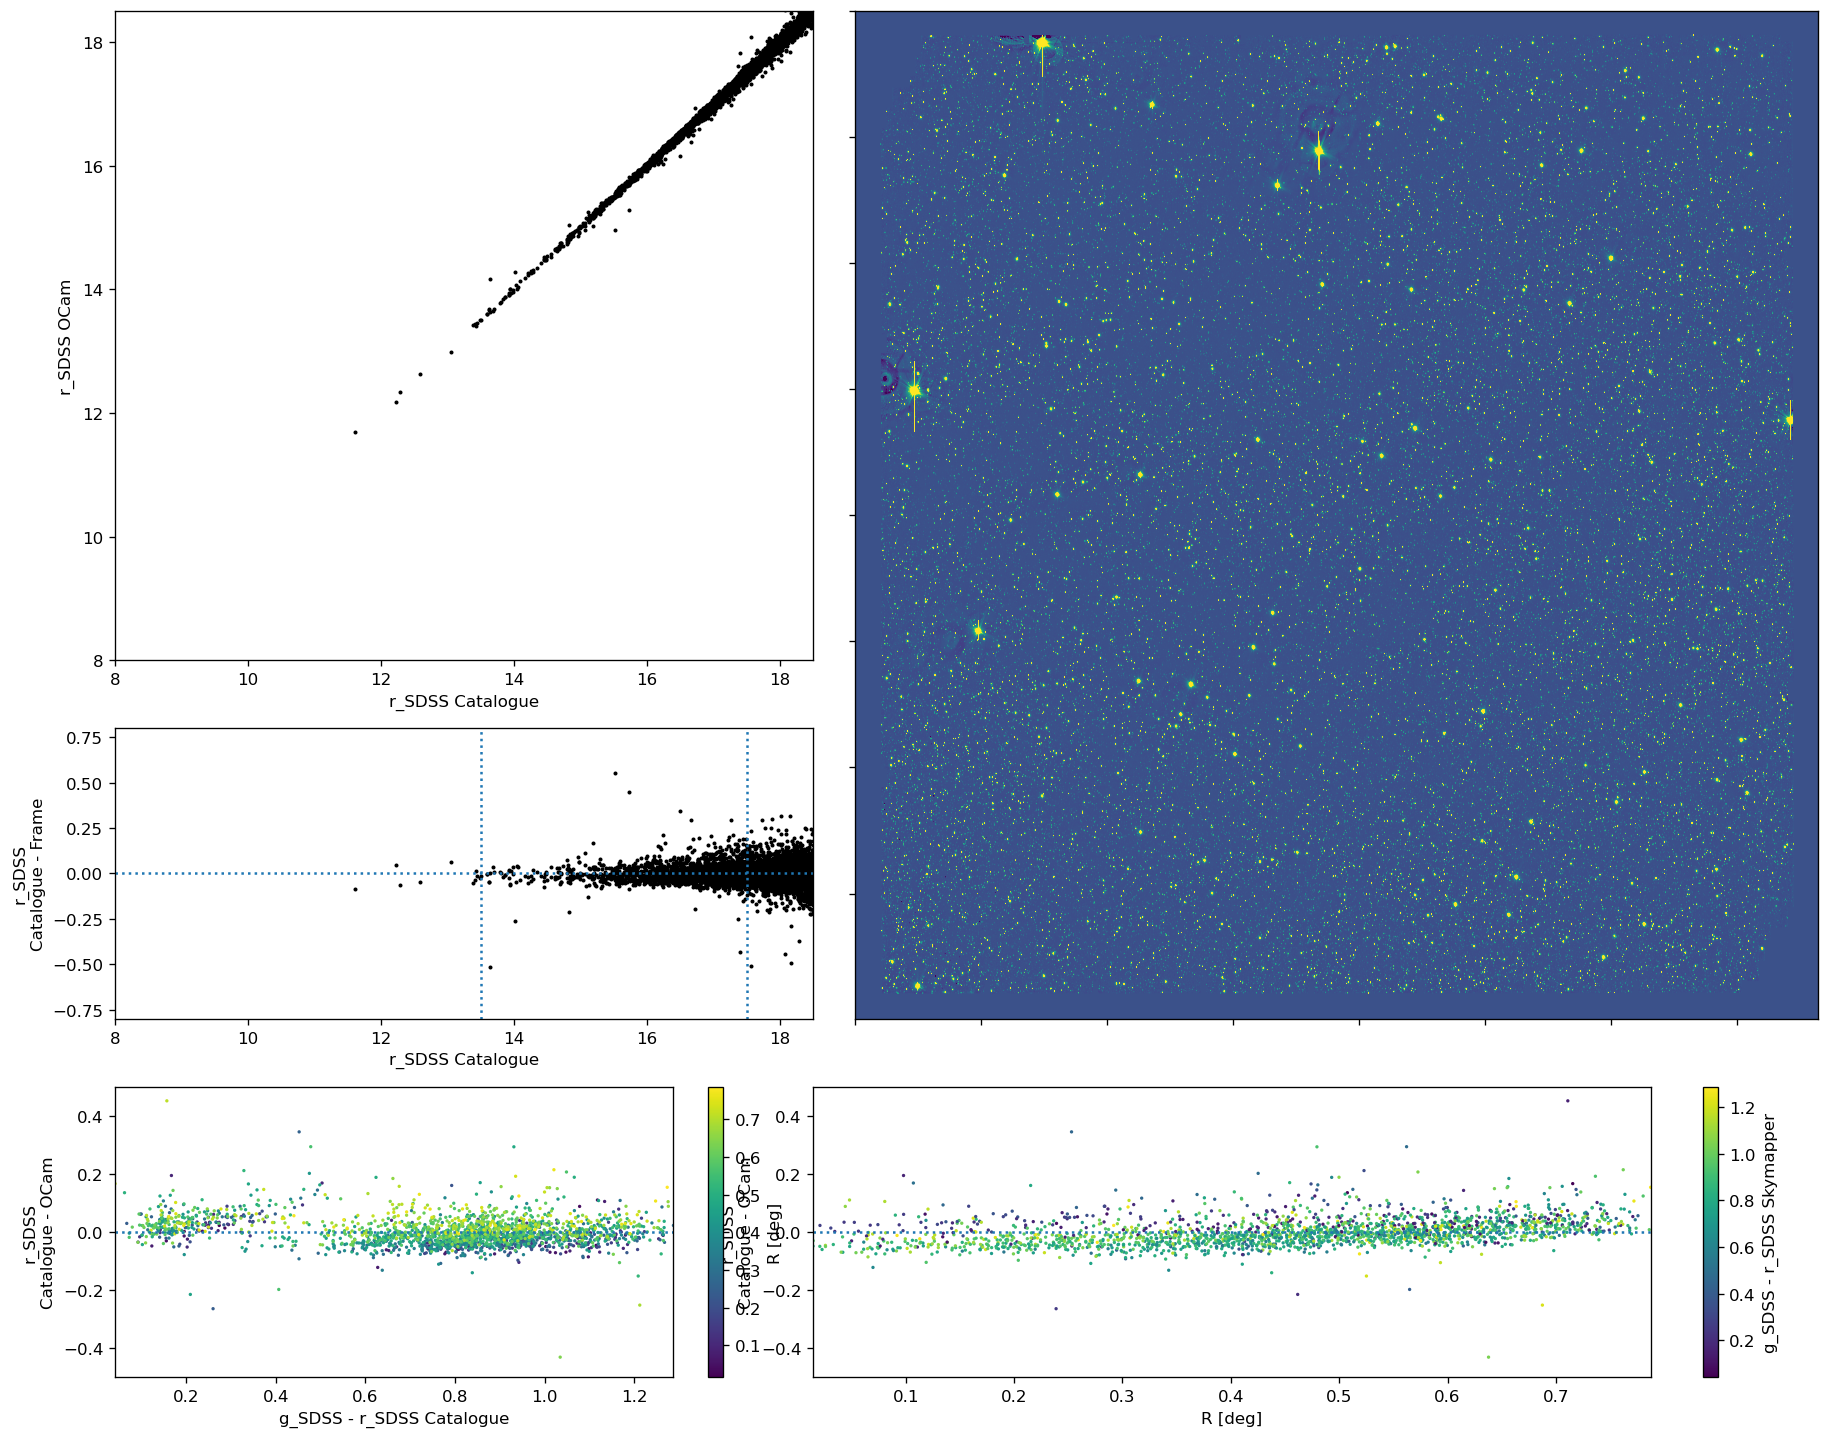

In [3]:
# set the directory folders
config_dir = os.getcwd()+'/config/'
config = pycavi_tools.read_pycavi_config(config_dir)
observatory = config['Provenance']['observatory'] # Needed for the atmospheric extinction curve
project_dir = config['Directories']['project_dir']
reduced_science_dir = config['Directories']['reduced_science_dir']  
log_dir = config['Directories']['project_logs_dir']


# Set the target explicitly. At this point it is believed that
# the data reduction process should be closely monitored, so
# we calibrate target/filter sets one by one.
#
# Eventually the choice of target should be done via GUI
#
target = 'CP_Pup_081146p060_m352105p0'
filter = 'r_SDSS'
sextractor_dir = reduced_science_dir+'/'+target+'/'+config['Directories']['sex_dir_name']
swarp_dir = reduced_science_dir+'/'+target+'/'+config['Directories']['swarp_dir_name']
calibration_dir = reduced_science_dir+'/'+target+'/'+config['Directories']['cal_dir_name']

log_file_swarp = log_dir + "/pymeffpp_swarp.log"
logging.basicConfig(level=logging.INFO,
                    format="%(asctime)s:%(levelname)s:%(message)s",
                    handlers=[
                              logging.FileHandler(log_file_swarp),
                              logging.StreamHandler()])
logging.getLogger().setLevel(logging.INFO)

# We create a list with the names of the registered and combined
# images output by the notebook 6 swarp. 
#
#images_to_calibrate = []
#for image in glob.glob(swarp_dir + "/*.list"):
#    images_to_calibrate.append(image[:-5]+".coadd.fits")
images_to_check = glob.glob(swarp_dir + '/*_'+filter+'.coadd.fits')
images_to_check.sort()

for image in images_to_check:

    plot_calibration_check(image, calibration_dir, swarp_dir)
    
logging.info("-------Done-------")